# The EV Adoption Puzzle: Time Series Forecasting

This notebook investigates the evolution of Battery Electric Vehicle (BEV) adoption across selected European countries using monthly data.

The analysis builds on the findings from the previous exploratory analysis and focuses on forecasting future adoption trends.

The main objective is to estimate how the share of newly registered passenger cars that are fully electric may evolve over time.

Norway, Switzerland and Spain are selected as contrasting examples of European EV markets.

The forecasting analysis uses historical monthly BEV data from Ember.

## Forecasting Objective

### Research Question

Where is BEV adoption accelerating in Europe, and what factors help explain the differences between countries?

### Machine Learning Objective

Forecast monthly BEV market share for selected European countries using historical registration patterns.

### Target Variable

`bev_share_pct`

This variable represents the percentage of newly registered passenger cars that are battery electric vehicles.

### Forecasting Horizon

The objective is to estimate BEV market share for the 12 months following the latest available common observation.

Forecasts are estimates based on historical patterns and should not be interpreted as guaranteed future outcomes.

In [3]:
# Import libraries
import pandas as pd
import numpy as np

from sklearn.datasets import fetch_california_housing

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.metrics import accuracy_score

from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
)

from sklearn.tree import DecisionTreeClassifier

from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Set a consistent visualization style
sns.set_theme(style="whitegrid")

In [4]:
# Load the cleaned monthly BEV registration dataset from Ember
ember_monthly = pd.read_csv("../data/cleaned/ember_bev_clean.csv")

# Convert the date column to datetime format
ember_monthly["date"] = pd.to_datetime(ember_monthly["date"])

# Sort observations chronologically within each country
ember_monthly = ember_monthly.sort_values(["country", "date"]).reset_index(drop=True)

# Display the first five observations
ember_monthly.head()

,country,country_code,date,bev_registrations,bev_share_pct,continent,ember_region,eu_member,year
0,Albania,ALB,2019-01-01,1.0,0.03,Europe,Europe,False,2019
1,Albania,ALB,2019-02-01,1.0,0.03,Europe,Europe,False,2019
2,Albania,ALB,2019-03-01,3.0,0.17,Europe,Europe,False,2019
3,Albania,ALB,2019-04-01,2.0,0.08,Europe,Europe,False,2019
4,Albania,ALB,2019-05-01,0.0,0.00,Europe,Europe,False,2019


In [5]:
# Inspect the dataset dimensions
print("Dataset shape:", ember_monthly.shape)

# Inspect column names, data types and non-null values
ember_monthly.info()

# Display the overall date range
print("Date range:", ember_monthly["date"].min(), "to", ember_monthly["date"].max())

# Count the number of countries represented
print("Number of countries:", ember_monthly["country"].nunique())

Dataset shape: (3630, 9)
<class 'pandas.DataFrame'>
RangeIndex: 3630 entries, 0 to 3629
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   country            3630 non-null   str           
 1   country_code       3630 non-null   str           
 2   date               3630 non-null   datetime64[us]
 3   bev_registrations  3630 non-null   float64       
 4   bev_share_pct      3630 non-null   float64       
 5   continent          3630 non-null   str           
 6   ember_region       3630 non-null   str           
 7   eu_member          3630 non-null   bool          
 8   year               3630 non-null   int64         
dtypes: bool(1), datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 310.1 KB
Date range: 2005-01-01 00:00:00 to 2026-10-01 00:00:00
Number of countries: 33


## Checking Data Availability

Before selecting countries for forecasting, the historical data coverage is examined.

Countries may have different starting dates and different numbers of available monthly observations.

The analysis checks the available date range, missing months and duplicate monthly records.

This helps ensure that the selected countries have sufficient historical data for time series modelling.

In [ ]:
# Examine monthly data coverage for all countries

coverage_results = []

for country in ember_monthly["country"].unique():

    country_data = ember_monthly[ember_monthly["country"] == country].copy()

    expected_dates = pd.date_range(
        start=country_data["date"].min(), end=country_data["date"].max(), freq="MS"
    )

    available_dates = pd.DatetimeIndex(country_data["date"].drop_duplicates())

    missing_dates = expected_dates.difference(available_dates)

    coverage_results.append(
        {
            "country": country,
            "observations": len(country_data),
            "start_date": country_data["date"].min(),
            "end_date": country_data["date"].max(),
            "expected_months": len(expected_dates),
            "missing_months": len(missing_dates),
            "duplicate_months": country_data["date"].duplicated().sum(),
        }
    )

country_coverage = pd.DataFrame(coverage_results)

country_coverage = country_coverage.sort_values(
    "observations", ascending=False
).reset_index(drop=True)

display(country_coverage)

,country,observations,start_date,end_date,expected_months,missing_months,duplicate_months
0,Norway,262,2005-01-01,2026-10-01,262,0,0
1,Switzerland,261,2005-01-01,2026-09-01,261,0,0
2,Sweden,249,2006-01-01,2026-09-01,249,0,0
3,Ireland,237,2007-01-01,2026-09-01,237,0,0
4,Luxembourg,201,2010-01-01,2026-09-01,201,0,0
5,Belgium,165,2013-01-01,2026-09-01,165,0,0
6,Ukraine,164,2013-01-01,2026-08-01,164,0,0
7,France,141,2015-01-01,2026-09-01,141,0,0
8,Denmark,141,2015-01-01,2026-09-01,141,0,0
9,Spain,141,2015-01-01,2026-09-01,141,0,0


### Selection of Countries

The forecasting analysis includes 32 European countries with at least 36 monthly observations and data available through September 2026.

A common observation period is used, from January 2015 to September 2026, where data are available. Countries with shorter historical coverage are included if they meet the minimum data requirement.

This approach allows the analysis to explore different stages of BEV market development across Europe, including established electric vehicle markets and countries where adoption is more recent.

The aim is to compare historical adoption patterns and evaluate different forecasting methods to explore potential developments in BEV market share over the following 12 months.

In [ ]:
# Define a common period for all countries
start_date = "2015-01-01"
end_date = "2026-09-01"

# Filter all countries by the common date range
forecast_data = ember_monthly[
    ember_monthly["date"].between(start_date, end_date)
].copy()

# Sort observations chronologically within each country
forecast_data = forecast_data.sort_values(["country", "date"]).reset_index(drop=True)

# Check dataset dimensions
print("Dataset shape:", forecast_data.shape)

# Check monthly observations and data quality for each country
country_summary = forecast_data.groupby("country").agg(
    observations=("date", "nunique"),
    start_date=("date", "min"),
    end_date=("date", "max"),
    missing_values=("bev_share_pct", lambda x: x.isna().sum()),
    duplicate_dates=("date", lambda x: x.duplicated().sum()),
)

display(country_summary)

Dataset shape: (3074, 9)


,observations,start_date,end_date,missing_values,duplicate_dates
country,,,,,
Albania,93,2019-01-01,2026-09-01,0,0
Austria,105,2018-01-01,2026-09-01,0,0
Belgium,141,2015-01-01,2026-09-01,0,0
Bulgaria,44,2023-01-01,2026-09-01,0,0
Croatia,45,2023-01-01,2026-09-01,0,0
Cyprus,45,2023-01-01,2026-09-01,0,0
Czechia,141,2015-01-01,2026-09-01,0,0
Denmark,141,2015-01-01,2026-09-01,0,0
Estonia,45,2023-01-01,2026-09-01,0,0


In [ ]:
# Keep countries with at least 36 monthly observations
# and data available through September 2026

eligible_countries = country_summary[
    (country_summary["observations"] >= 36)
    & (country_summary["end_date"] == pd.Timestamp("2026-09-01"))
].index.tolist()

forecast_data = forecast_data[forecast_data["country"].isin(eligible_countries)].copy()

print("Eligible countries:", len(eligible_countries))
print(sorted(eligible_countries))

Eligible countries: 32
['Albania', 'Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'Ireland', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'Romania', 'Slovakia', 'Slovenia', 'Spain', 'Sweden', 'Switzerland', 'United Kingdom']


## Exploratory Analysis of BEV Market Share

The historical evolution of BEV market share is examined across 32 European countries between January 2015 and September 2026, depending on data availability.

The analysis focuses on two dimensions:

1. **Adoption level:** The percentage of newly registered passenger cars that are fully electric (BEVs).
2. **Adoption momentum:** How quickly BEV market share changes over time.

The objective is to identify differences in adoption patterns across European markets and assess whether historical trends can support future forecasting.

In [9]:
# Select the latest 12 monthly observations for each country
recent_data = forecast_data.groupby("country").tail(12).sort_values(["country", "date"])

# Display recent registrations and BEV market share
recent_data[["country", "date", "bev_registrations", "bev_share_pct"]]

,country,date,bev_registrations,bev_share_pct
81,Albania,2025-10-01,653.0,9.28
82,Albania,2025-11-01,617.0,11.29
83,Albania,2025-12-01,836.0,10.90
84,Albania,2026-01-01,753.0,13.27
85,Albania,2026-02-01,858.0,14.53
...,...,...,...,...
3069,United Kingdom,2026-05-01,43931.0,27.34
3070,United Kingdom,2026-06-01,63950.0,30.00
3071,United Kingdom,2026-07-01,43106.0,27.53
3072,United Kingdom,2026-08-01,28063.0,29.78


## Identifying Long-Term Adoption Trends

Monthly BEV market share can fluctuate considerably due to short-term changes in vehicle registrations.

A 12-month rolling average is calculated separately for each country to smooth these fluctuations and make longer-term adoption trends easier to identify.

This helps distinguish sustained changes in adoption from temporary monthly variations.

In [ ]:
# Calculate the 12-month rolling average of BEV market share for each country
forecast_data["bev_share_12m_avg"] = forecast_data.groupby("country")[
    "bev_share_pct"
].transform(lambda series: series.rolling(window=12, min_periods=12).mean())

# Display the latest rolling averages for each country
display(
    forecast_data.groupby("country").tail(1)[
        ["country", "date", "bev_share_pct", "bev_share_12m_avg"]
    ]
)

,country,date,bev_share_pct,bev_share_12m_avg
92,Albania,2026-09-01,10.89,11.954167
197,Austria,2026-09-01,33.56,24.698333
338,Belgium,2026-09-01,50.87,39.538333
382,Bulgaria,2026-09-01,13.57,7.630000
427,Croatia,2026-09-01,3.50,4.150833
472,Cyprus,2026-09-01,8.04,10.673333
613,Czechia,2026-09-01,11.21,6.900833
754,Denmark,2026-09-01,88.61,79.707500
799,Estonia,2026-09-01,11.18,7.327500
928,Finland,2026-09-01,62.11,48.127500


### Key Observations: Long-Term Adoption Trends

The 12-month rolling averages provide a smoother representation of BEV adoption across European countries.

The historical trends highlight differences in:
- Overall BEV adoption levels.
- The maturity of individual electric vehicle markets.
- The pace of recent adoption changes.

Countries with established BEV markets may show signs of approaching saturation, while countries with lower adoption levels may have greater potential for future growth.

Rolling averages help distinguish sustained adoption patterns from temporary monthly fluctuations.

## Time Series Forecasting

The historical analysis revealed different patterns of BEV adoption across European countries.

Time series forecasting is used to estimate future values based on historical observations and patterns over time.

The objective is to forecast monthly BEV market share for 32 eligible European countries over a 12-month period, from October 2026 to September 2027.

Three forecasting approaches will be compared:

- **Naive Forecast:** Uses the latest observed value as the forecast for future months.
- **Seasonal Naive Forecast:** Uses the value from the same month in the previous year.
- **Holt-Winters Exponential Smoothing:** Models the underlying level, trend and monthly seasonality in the time series.

To evaluate the forecasting approaches, the final 12 months of historical data will be reserved as a test period. The models will be trained on earlier observations and evaluated against actual values in the test period.

The best-performing approach will be selected individually for each country and used to generate the final 12-month forecasts.

### Preparing the Time Series Data

The dataset is prepared separately for each eligible country. The monthly date is set as the time index, allowing the forecasting models to recognise the chronological order of observations.

The target variable is `bev_share_pct`, representing the percentage of newly registered passenger cars that are battery electric vehicles (BEVs).

In [31]:
# Prepare a monthly time series for each eligible country

country_series = {}

for country in forecast_data["country"].unique():

    country_df = forecast_data[forecast_data["country"] == country].copy()

    country_df = country_df.sort_values("date")
    country_df = country_df.set_index("date")

    country_series[country] = (
        country_df["bev_share_pct"]
        .asfreq("MS")
        .interpolate(method="time", limit=1, limit_area="inside")
    )
# Check the number of observations for each country

for country, series in country_series.items():
    print(f"{country}: {len(series)} monthly observations")

print("\nTotal countries:", len(country_series))

Albania: 93 monthly observations
Austria: 105 monthly observations
Belgium: 141 monthly observations
Bulgaria: 45 monthly observations
Croatia: 45 monthly observations
Cyprus: 45 monthly observations
Czechia: 141 monthly observations
Denmark: 141 monthly observations
Estonia: 45 monthly observations
Finland: 129 monthly observations
France: 141 monthly observations
Germany: 117 monthly observations
Greece: 45 monthly observations
Hungary: 45 monthly observations
Iceland: 45 monthly observations
Ireland: 141 monthly observations
Italy: 93 monthly observations
Latvia: 45 monthly observations
Lithuania: 45 monthly observations
Luxembourg: 141 monthly observations
Malta: 45 monthly observations
Netherlands: 105 monthly observations
Norway: 141 monthly observations
Poland: 105 monthly observations
Portugal: 93 monthly observations
Romania: 45 monthly observations
Slovakia: 45 monthly observations
Slovenia: 45 monthly observations
Spain: 141 monthly observations
Sweden: 141 monthly observati

### Train-Test Split

The data is divided chronologically into training and testing periods.

For each country, the available observations up to September 2025 are used for training. The final 12 months, from October 2025 to September 2026, are reserved for testing.

This approach simulates forecasting future values using only information available at the end of September 2025.

The starting date of the training period varies depending on each country's historical data availability.

In [32]:
# Split each country's time series into training and testing periods

train_data = {}
test_data = {}

for country, series in country_series.items():
    train_data[country] = series.loc[:"2025-09-01"]
    test_data[country] = series.loc["2025-10-01":]

# Check the number of observations in each period
for country in country_series:
    print(
        f"{country}: "
        f"{len(train_data[country])} training observations, "
        f"{len(test_data[country])} testing observations"
    )

Albania: 81 training observations, 12 testing observations
Austria: 93 training observations, 12 testing observations
Belgium: 129 training observations, 12 testing observations
Bulgaria: 33 training observations, 12 testing observations
Croatia: 33 training observations, 12 testing observations
Cyprus: 33 training observations, 12 testing observations
Czechia: 129 training observations, 12 testing observations
Denmark: 129 training observations, 12 testing observations
Estonia: 33 training observations, 12 testing observations
Finland: 117 training observations, 12 testing observations
France: 129 training observations, 12 testing observations
Germany: 105 training observations, 12 testing observations
Greece: 33 training observations, 12 testing observations
Hungary: 33 training observations, 12 testing observations
Iceland: 33 training observations, 12 testing observations
Ireland: 129 training observations, 12 testing observations
Italy: 81 training observations, 12 testing observa

### Naive Forecast

The Naive Forecast assumes that the latest observed BEV market share will remain unchanged throughout the forecast period.

The most recent value in the training dataset is used as the prediction for all 12 months in the testing period.

This simple approach serves as a baseline for evaluating the performance of the other forecasting methods.

In [33]:
# Generate a 12-month Naive Forecast for each country

naive_forecasts = {}

for country in train_data:
    last_value = train_data[country].iloc[-1]

    naive_forecasts[country] = pd.Series(last_value, index=test_data[country].index)

# Display the forecasts
for country, forecast in naive_forecasts.items():
    print(f"\n{country}")
    print(forecast)


Albania
date
2025-10-01    8.78
2025-11-01    8.78
2025-12-01    8.78
2026-01-01    8.78
2026-02-01    8.78
2026-03-01    8.78
2026-04-01    8.78
2026-05-01    8.78
2026-06-01    8.78
2026-07-01    8.78
2026-08-01    8.78
2026-09-01    8.78
Freq: MS, dtype: float64

Austria
date
2025-10-01    20.91
2025-11-01    20.91
2025-12-01    20.91
2026-01-01    20.91
2026-02-01    20.91
2026-03-01    20.91
2026-04-01    20.91
2026-05-01    20.91
2026-06-01    20.91
2026-07-01    20.91
2026-08-01    20.91
2026-09-01    20.91
Freq: MS, dtype: float64

Belgium
date
2025-10-01    37.96
2025-11-01    37.96
2025-12-01    37.96
2026-01-01    37.96
2026-02-01    37.96
2026-03-01    37.96
2026-04-01    37.96
2026-05-01    37.96
2026-06-01    37.96
2026-07-01    37.96
2026-08-01    37.96
2026-09-01    37.96
Freq: MS, dtype: float64

Bulgaria
date
2025-10-01    5.92
2025-11-01    5.92
2025-12-01    5.92
2026-01-01    5.92
2026-02-01    5.92
2026-03-01    5.92
2026-04-01    5.92
2026-05-01    5.92
2026-06-

### Seasonal Naive Forecast

The Seasonal Naive Forecast assumes that seasonal patterns repeat over time.

For monthly data, each forecasted value is based on the observation from the same month in the previous year.

A seasonal period of 12 months is therefore used. This approach accounts for recurring monthly patterns, unlike the Naive Forecast, which keeps the forecast constant.

In [34]:
# Generate a 12-month Seasonal Naive Forecast for each country

seasonal_naive_forecasts = {}

for country in train_data:
    seasonal_values = train_data[country].iloc[-12:].values

    seasonal_naive_forecasts[country] = pd.Series(
        seasonal_values, index=test_data[country].index
    )

# Display the forecasts
for country, forecast in seasonal_naive_forecasts.items():
    print(f"\n{country}")
    print(forecast)


Albania
date
2025-10-01    5.09
2025-11-01    4.99
2025-12-01    4.06
2026-01-01    5.96
2026-02-01    5.73
2026-03-01    4.86
2026-04-01    3.76
2026-05-01    3.96
2026-06-01    7.71
2026-07-01    5.73
2026-08-01    6.40
2026-09-01    8.78
Freq: MS, dtype: float64

Austria
date
2025-10-01    18.15
2025-11-01    19.57
2025-12-01    19.66
2026-01-01    18.69
2026-02-01    21.58
2026-03-01    23.59
2026-04-01    22.89
2026-05-01    22.33
2026-06-01    22.39
2026-07-01    19.79
2026-08-01    20.11
2026-09-01    20.91
Freq: MS, dtype: float64

Belgium
date
2025-10-01    34.95
2025-11-01    35.34
2025-12-01    31.74
2026-01-01    33.78
2026-02-01    32.47
2026-03-01    33.97
2026-04-01    32.98
2026-05-01    33.05
2026-06-01    30.73
2026-07-01    32.25
2026-08-01    34.76
2026-09-01    37.96
Freq: MS, dtype: float64

Bulgaria
date
2025-10-01    4.46
2025-11-01    5.03
2025-12-01    4.14
2026-01-01    5.11
2026-02-01    3.71
2026-03-01    5.36
2026-04-01    3.59
2026-05-01    5.11
2026-06-

### Holt-Winters Exponential Smoothing

Holt-Winters Exponential Smoothing is a forecasting method that models the level, trend and seasonality of a time series.

The model uses historical observations to estimate these components and project future values.

For this analysis, an additive trend and additive seasonal component will be tested, using a seasonal period of 12 months to represent annual patterns in monthly BEV market share.

In [35]:
# Fit a Holt-Winters model for each country and forecast 12 months

holt_winters_forecasts = {}
holt_winters_models = {}

for country in train_data:

    # Define the model using an additive trend and seasonality
    model = ExponentialSmoothing(
        train_data[country],
        trend="add",
        seasonal="add",
        seasonal_periods=12,
        initialization_method="estimated",
    )

    # Fit the model to the training data
    fitted_model = model.fit()

    # Forecast the 12 months in the test period
    forecast = fitted_model.forecast(12)

    # Store the fitted model and forecast
    holt_winters_models[country] = fitted_model
    holt_winters_forecasts[country] = forecast

# Display the forecasts
for country, forecast in holt_winters_forecasts.items():
    print(f"\n{country}")
    print(forecast.round(2))


Albania
2025-10-01    7.51
2025-11-01    7.56
2025-12-01    7.62
2026-01-01    8.30
2026-02-01    8.84
2026-03-01    8.25
2026-04-01    8.13
2026-05-01    8.19
2026-06-01    8.82
2026-07-01    8.59
2026-08-01    9.23
2026-09-01    9.80
Freq: MS, dtype: float64

Austria
2025-10-01    19.60
2025-11-01    21.33
2025-12-01    22.12
2026-01-01    18.39
2026-02-01    19.70
2026-03-01    21.17
2026-04-01    19.52
2026-05-01    19.98
2026-06-01    20.30
2026-07-01    19.50
2026-08-01    21.25
2026-09-01    24.00
Freq: MS, dtype: float64

Belgium
2025-10-01    33.98
2025-11-01    35.37
2025-12-01    35.44
2026-01-01    35.31
2026-02-01    34.09
2026-03-01    36.94
2026-04-01    35.43
2026-05-01    36.57
2026-06-01    36.16
2026-07-01    38.30
2026-08-01    41.34
2026-09-01    42.47
Freq: MS, dtype: float64

Bulgaria
2025-10-01    5.69
2025-11-01    6.23
2025-12-01    6.04
2026-01-01    5.85
2026-02-01    5.68
2026-03-01    6.01
2026-04-01    5.74
2026-05-01    6.28
2026-06-01    6.50
2026-07-0

### Evaluating Forecast Accuracy

The forecasting methods are evaluated by comparing their predictions with the actual BEV market shares during the 12-month test period.

Two evaluation metrics are used:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between predicted and actual values.
- **Root Mean Squared Error (RMSE):** Measures the square root of the average squared prediction errors, giving greater weight to larger errors.

Lower MAE and RMSE values indicate better forecasting accuracy.

In [36]:
# Store the forecasts for comparison
forecast_methods = {
    "Naive": naive_forecasts,
    "Seasonal Naive": seasonal_naive_forecasts,
    "Holt-Winters": holt_winters_forecasts,
}

# Check for missing values in actual data and forecasts
nan_found = False

for country in test_data:

    actual = test_data[country]

    if actual.isna().any():
        print(f"NaN in actual data: {country}")
        nan_found = True

    for method_name, forecasts in forecast_methods.items():

        predicted = forecasts[country]

        if predicted.isna().any():
            print(f"NaN in {method_name} forecast: {country}")
            nan_found = True

if not nan_found:
    print("No missing values found in actual data or forecasts.")

No missing values found in actual data or forecasts.


In [37]:
# Calculate MAE and RMSE for each country and method
results = []

for country in test_data:

    actual = test_data[country]

    for method_name, forecasts in forecast_methods.items():

        predicted = forecasts[country]

        mae = mean_absolute_error(actual, predicted)
        rmse = mean_squared_error(actual, predicted) ** 0.5

        results.append(
            {"Country": country, "Method": method_name, "MAE": mae, "RMSE": rmse}
        )

# Create a results DataFrame
forecast_results = pd.DataFrame(results)

display(forecast_results.round(2))

,Country,Method,MAE,RMSE
0,Albania,Naive,3.31,4.47
1,Albania,Seasonal Naive,6.37,7.48
2,Albania,Holt-Winters,3.66,4.84
3,Austria,Naive,3.98,5.48
4,Austria,Seasonal Naive,4.02,5.39
...,...,...,...,...
91,Switzerland,Seasonal Naive,5.21,6.06
92,Switzerland,Holt-Winters,3.31,4.18
93,United Kingdom,Naive,4.01,4.66
94,United Kingdom,Seasonal Naive,3.61,4.13


### Key Findings: Forecast Model Evaluation

The evaluation results show that forecasting accuracy varies across European countries.

The three forecasting methods are compared individually for each country using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

The best-performing model is selected for each country based on the lowest MAE. This approach allows the forecasting method to reflect the individual adoption patterns of each market.

The results highlight the importance of evaluating forecasting methods at country level rather than applying a single model across all countries.

In [ ]:
# Select the best-performing forecasting model for each country

best_models = (
    forecast_results.loc[forecast_results.groupby("Country")["MAE"].idxmin()]
    .sort_values("Country")
    .reset_index(drop=True)
)

# Display the selected model and its evaluation metrics
display(best_models.round(2))

# Check the number of countries evaluated
print("Countries evaluated:", best_models["Country"].nunique())

# Count how often each forecasting method was selected
print("\nBest model distribution:")
display(best_models["Method"].value_counts())

,Country,Method,MAE,RMSE
0,Albania,Naive,3.31,4.47
1,Austria,Naive,3.98,5.48
2,Belgium,Holt-Winters,3.37,4.11
3,Bulgaria,Holt-Winters,1.95,2.75
4,Croatia,Naive,0.53,0.80
5,Cyprus,Naive,3.70,4.31
6,Czechia,Holt-Winters,1.35,1.80
7,Denmark,Holt-Winters,2.40,3.47
8,Estonia,Naive,1.76,2.84
9,Finland,Naive,7.05,8.25


Countries evaluated: 32

Best model distribution:


Method
Holt-Winters      17
Naive             13
Seasonal Naive     2
Name: count, dtype: int64

### Key Findings: Forecast Model Evaluation

The evaluation results show that forecasting accuracy varies across European countries.

Holt-Winters was selected as the best-performing method for 17 countries, followed by the Naive Forecast for 13 countries. The Seasonal Naive Forecast performed best for two countries.

These results demonstrate that no single forecasting method performs best across all European markets.

The Naive Forecast performed particularly well in some countries, suggesting that recent market share levels can provide a strong baseline. In other countries, modelling trend and seasonality through Holt-Winters resulted in lower prediction errors.

The best-performing method was therefore selected individually for each country based on its lowest MAE.

### Generating the Final 12-Month Forecasts

Following the evaluation, the best-performing forecasting method is selected separately for each country.

The selected methods are refitted using the complete historical dataset, including observations up to September 2026.

The models are then used to forecast monthly BEV market share from October 2026 to September 2027.

In [42]:
# Generate future forecasts using the best model for each country

final_forecasts = {}

forecast_dates = pd.date_range(start="2026-10-01", periods=12, freq="MS")

for country, series in country_series.items():

    # Retrieve the best-performing model for this country
    best_method = best_models.loc[best_models["Country"] == country, "Method"].iloc[0]

    if best_method == "Naive":

        forecast = pd.Series(series.iloc[-1], index=forecast_dates)

    elif best_method == "Seasonal Naive":

        forecast = pd.Series(series.iloc[-12:].values, index=forecast_dates)

    elif best_method == "Holt-Winters":

        model = ExponentialSmoothing(
            series,
            trend="add",
            seasonal="add",
            seasonal_periods=12,
            initialization_method="estimated",
        )

        fitted_model = model.fit()
        forecast = fitted_model.forecast(12)

        forecast.index = forecast_dates

    # Keep forecasts within the valid market-share range (0–100%)
    forecast = forecast.clip(lower=0, upper=100)

    # Store the final forecast
    final_forecasts[country] = forecast

# Display the final forecasts
for country, forecast in final_forecasts.items():
    print(f"\n{country}")
    print(forecast.round(2))


Albania
2026-10-01    10.89
2026-11-01    10.89
2026-12-01    10.89
2027-01-01    10.89
2027-02-01    10.89
2027-03-01    10.89
2027-04-01    10.89
2027-05-01    10.89
2027-06-01    10.89
2027-07-01    10.89
2027-08-01    10.89
2027-09-01    10.89
Freq: MS, dtype: float64

Austria
2026-10-01    33.56
2026-11-01    33.56
2026-12-01    33.56
2027-01-01    33.56
2027-02-01    33.56
2027-03-01    33.56
2027-04-01    33.56
2027-05-01    33.56
2027-06-01    33.56
2027-07-01    33.56
2027-08-01    33.56
2027-09-01    33.56
Freq: MS, dtype: float64

Belgium
2026-10-01    47.10
2026-11-01    49.88
2026-12-01    48.04
2027-01-01    47.42
2027-02-01    45.74
2027-03-01    50.47
2027-04-01    50.08
2027-05-01    50.63
2027-06-01    50.82
2027-07-01    53.81
2027-08-01    56.41
2027-09-01    57.89
Freq: MS, dtype: float64

Bulgaria
2026-10-01    12.01
2026-11-01    13.01
2026-12-01    13.56
2027-01-01    14.15
2027-02-01    14.64
2027-03-01    16.00
2027-04-01    16.85
2027-05-01    17.54
2027-06-

Forecast values are constrained to the valid range of 0% to 100%, as BEV market share cannot fall outside these boundaries. This adjustment prevents mathematically generated predictions from exceeding realistic market-share limits.

Forecast uncertainty is particularly relevant for countries with volatile historical registration patterns.

In [43]:
# Validate the final forecasts for all countries

forecast_summary = []

for country, forecast in final_forecasts.items():

    forecast_summary.append(
        {
            "Country": country,
            "Forecast months": len(forecast),
            "Minimum forecast": forecast.min(),
            "Maximum forecast": forecast.max(),
            "Missing values": forecast.isna().sum(),
            "Above 100%": (forecast > 100).sum(),
            "Below 0%": (forecast < 0).sum(),
        }
    )

forecast_validation = pd.DataFrame(forecast_summary)

display(forecast_validation.round(2))

print("Total countries:", len(final_forecasts))
print("Total forecast observations:", sum(len(x) for x in final_forecasts.values()))

,Country,Forecast months,Minimum forecast,Maximum forecast,Missing values,Above 100%,Below 0%
0,Albania,12,10.89,10.89,0,0,0
1,Austria,12,33.56,33.56,0,0,0
2,Belgium,12,45.74,57.89,0,0,0
3,Bulgaria,12,12.01,21.27,0,0,0
4,Croatia,12,3.50,3.50,0,0,0
5,Cyprus,12,8.04,8.04,0,0,0
6,Czechia,12,9.67,11.00,0,0,0
7,Denmark,12,86.83,100.00,0,0,0
8,Estonia,12,11.18,11.18,0,0,0
9,Finland,12,62.11,62.11,0,0,0


Total countries: 32
Total forecast observations: 384


In [ ]:
# Inspect historical and forecasted BEV market share
# for countries with unusual forecast behaviour

countries_to_inspect = ["Denmark", "Iceland", "Ireland", "Netherlands", "Malta"]

for country in countries_to_inspect:

    print(f"\n--- {country} ---")

    print("\nLast 24 historical observations:")
    display(country_series[country].tail(24).round(2))

    print("\nFinal 12-month forecast:")
    display(final_forecasts[country].round(2))


--- Denmark ---

Last 24 historical observations:


date
2024-10-01    61.29
2024-11-01    58.57
2024-12-01    61.62
2025-01-01    64.07
2025-02-01    66.08
2025-03-01    65.25
2025-04-01    62.74
2025-05-01    60.57
2025-06-01    63.35
2025-07-01    66.74
2025-08-01    68.65
2025-09-01    73.07
2025-10-01    70.44
2025-11-01    73.55
2025-12-01    80.69
2026-01-01    82.41
2026-02-01    80.66
2026-03-01    76.58
2026-04-01    81.47
2026-05-01    78.32
2026-06-01    78.72
2026-07-01    79.48
2026-08-01    85.56
2026-09-01    88.61
Freq: MS, Name: bev_share_pct, dtype: float64


Final 12-month forecast:


2026-10-01     86.83
2026-11-01     89.29
2026-12-01     94.76
2027-01-01     89.75
2027-02-01     91.44
2027-03-01     93.32
2027-04-01     92.74
2027-05-01     93.89
2027-06-01     95.89
2027-07-01     96.31
2027-08-01     99.65
2027-09-01    103.07
Freq: MS, dtype: float64


--- Iceland ---

Last 24 historical observations:


date
2024-10-01    57.18
2024-11-01    52.96
2024-12-01    36.69
2025-01-01    38.05
2025-02-01    37.86
2025-03-01    47.63
2025-04-01    23.54
2025-05-01    18.07
2025-06-01    30.46
2025-07-01    40.75
2025-08-01    50.50
2025-09-01    72.00
2025-10-01    48.75
2025-11-01    62.63
2025-12-01    57.95
2026-01-01    13.07
2026-02-01    39.63
2026-03-01    48.17
2026-04-01    44.53
2026-05-01    51.00
2026-06-01    56.22
2026-07-01    53.66
2026-08-01    78.18
2026-09-01    81.59
Freq: MS, Name: bev_share_pct, dtype: float64

... (10 outputs left out)


--- Malta ---

Last 24 historical observations:


date
2024-10-01    24.57
2024-11-01    24.41
2024-12-01    67.94
2025-01-01    32.97
2025-02-01    15.18
2025-03-01    26.87
2025-04-01    30.50
2025-05-01    24.41
2025-06-01    23.57
2025-07-01    19.35
2025-08-01    27.04
2025-09-01    28.07
2025-10-01    28.14
2025-11-01    21.65
2025-12-01    44.28
2026-01-01    25.27
2026-02-01    21.50
2026-03-01    22.89
2026-04-01    23.27
2026-05-01    36.38
2026-06-01    38.13
2026-07-01    45.99
2026-08-01    40.54
2026-09-01    44.99
Freq: MS, Name: bev_share_pct, dtype: float64


Final 12-month forecast:


2026-10-01    41.92
2026-11-01    40.57
2026-12-01    63.02
2027-01-01    44.16
2027-02-01    38.98
2027-03-01    42.22
2027-04-01    46.23
2027-05-01    47.41
2027-06-01    48.24
2027-07-01    47.63
2027-08-01    48.34
2027-09-01    50.76
Freq: MS, dtype: float64

In [44]:
# Combine all country forecasts into one DataFrame

forecast_records = []

for country, forecast in final_forecasts.items():
    for date, value in forecast.items():
        forecast_records.append({
            "country": country,
            "date": date,
            "forecast_bev_share_pct": value
        })

final_forecast_df = pd.DataFrame(forecast_records)

final_forecast_df = final_forecast_df.sort_values(
    ["country", "date"]
).reset_index(drop=True)

display(final_forecast_df.head(15))

print("Dataset shape:", final_forecast_df.shape)
print("Countries:", final_forecast_df["country"].nunique())
print("Forecast observations:", len(final_forecast_df))

,country,date,forecast_bev_share_pct
0,Albania,2026-10-01,10.89
1,Albania,2026-11-01,10.89
2,Albania,2026-12-01,10.89
3,Albania,2027-01-01,10.89
4,Albania,2027-02-01,10.89
5,Albania,2027-03-01,10.89
6,Albania,2027-04-01,10.89
7,Albania,2027-05-01,10.89
8,Albania,2027-06-01,10.89
9,Albania,2027-07-01,10.89


Dataset shape: (384, 3)
Countries: 32
Forecast observations: 384


### Key Findings: Future BEV Market Share Forecasts

The 12-month forecasts reveal different projected adoption patterns across the 32 European countries.

The evaluation shows that no single forecasting method performs best across all countries:
- Holt-Winters was selected for 17 countries.
- The Naive Forecast was selected for 13 countries.
- The Seasonal Naive Forecast was selected for 2 countries.

The projections also highlight differences in market maturity. Countries with already high BEV market shares, such as Norway, have more limited room for further growth, while other markets show potential for continued adoption.

Forecast trajectories vary considerably between countries. Smaller markets with volatile monthly registration patterns should be interpreted with particular caution.

The forecasts represent estimates based on historical patterns and should not be interpreted as guaranteed future outcomes.

### Limitations of the Forecasting Analysis

The forecasting analysis has several limitations that should be considered when interpreting the results.

- **Historical dependency:** The models rely on historical BEV market share and assume that past patterns provide useful information about future adoption.
- **External factors:** Government incentives, charging infrastructure, vehicle prices, electricity prices and economic conditions are not included as explanatory variables in the forecasting models.
- **Model limitations:** Only three forecasting approaches were compared. Selecting the model with the lowest MAE does not guarantee that it will remain the most accurate in the future.
- **Evaluation period:** Model selection is based on a single 12-month test period, which may not capture all possible market conditions.
- **Market saturation:** Countries such as Norway are already close to 100% BEV market share, limiting the potential for further growth.
- **Data variability:** Monthly registration patterns can be volatile, particularly in countries with smaller vehicle markets. One missing monthly observation for Bulgaria was interpolated.

Consequently, the forecasts should be interpreted as estimates based on historical trends rather than precise predictions of future market developments.

### Measuring BEV Adoption Momentum Across Europe

To complement the forecasting analysis, BEV adoption momentum is examined across all available European countries.

Adoption momentum measures the change in BEV market share compared with the same month in the previous year.

This analysis helps identify countries experiencing faster adoption growth and countries where adoption is slowing down.

The comparison expands the analysis beyond the three selected case studies and provides a broader overview of the European BEV market.

In [45]:
# Inspect the full monthly dataset before calculating adoption momentum

print("Dataset shape:", ember_monthly.shape)
print("Number of countries:", ember_monthly["country"].nunique())
print("Date range:", ember_monthly["date"].min(), "to", ember_monthly["date"].max())

# Check the available monthly observations for each country
momentum_country_coverage = (
    ember_monthly.groupby("country")["date"]
    .agg(first_month="min", last_month="max", observations="nunique")
    .sort_values("first_month")
)

display(momentum_country_coverage)

Dataset shape: (3630, 9)
Number of countries: 33
Date range: 2005-01-01 00:00:00 to 2026-10-01 00:00:00


,first_month,last_month,observations
country,,,
Switzerland,2005-01-01,2026-09-01,261
Norway,2005-01-01,2026-10-01,262
Sweden,2006-01-01,2026-09-01,249
Ireland,2007-01-01,2026-09-01,237
Luxembourg,2010-01-01,2026-09-01,201
Belgium,2013-01-01,2026-09-01,165
Ukraine,2013-01-01,2026-08-01,164
Spain,2015-01-01,2026-09-01,141
Czechia,2015-01-01,2026-09-01,141


### Calculating Year-over-Year BEV Market Share Changes

Adoption momentum is measured by comparing monthly BEV market share with the value recorded in the same month of the previous year.

The difference is expressed in percentage points (pp), rather than percentage change.

A positive value indicates that BEV market share has increased over the previous year, while a negative value indicates a decline.

September 2026 is selected as the common comparison month. The comparison includes countries with available observations for both September 2026 and September 2025. Countries without the required observations are excluded.

In [46]:
# Create a copy of the monthly BEV data
momentum_data = ember_monthly[["country", "date", "bev_share_pct"]].copy()

# Create a lookup table for the previous year's market share
previous_year = momentum_data.copy()

# Shift dates forward by one year to match the correct calendar month
previous_year["date"] = previous_year["date"] + pd.DateOffset(years=1)

# Rename the market share column
previous_year = previous_year.rename(
    columns={"bev_share_pct": "bev_share_previous_year"}
)

# Match observations by country and exact calendar date
momentum_data = momentum_data.merge(previous_year, on=["country", "date"], how="left")

# Calculate year-over-year change in percentage points
momentum_data["bev_share_yoy_change_pp"] = (
    momentum_data["bev_share_pct"] - momentum_data["bev_share_previous_year"]
)

# Select September 2026
september_2026 = (
    momentum_data[momentum_data["date"] == "2026-09-01"]
    .dropna(subset=["bev_share_previous_year"])
    .copy()
)

# Display the comparison
september_2026[
    ["country", "bev_share_previous_year", "bev_share_pct", "bev_share_yoy_change_pp"]
].sort_values("bev_share_yoy_change_pp", ascending=False).round(2)

,country,bev_share_previous_year,bev_share_pct,bev_share_yoy_change_pp
1093,France,22.06,41.07,19.01
952,Finland,43.21,62.11,18.90
2578,Portugal,29.32,48.05,18.73
1583,Ireland,30.93,49.29,18.36
2012,Malta,28.07,44.99,16.92
778,Denmark,73.07,88.61,15.54
1210,Germany,19.32,34.50,15.18
2117,Netherlands,37.69,52.81,15.12
362,Belgium,37.96,50.87,12.91
197,Austria,20.91,33.56,12.65


### Key Findings: European BEV Adoption Momentum

The September 2026 comparison reveals substantial differences in year-over-year BEV market share growth across the 32 European countries.

- **France, Finland and Portugal** recorded the strongest increases, with gains of 19.01, 18.90 and 18.73 percentage points respectively, compared with September 2025.
- **Ireland, Malta and Denmark** also experienced strong growth, with increases exceeding 15 percentage points.
- **Norway** recorded a relatively small increase of 0.52 percentage points, despite maintaining the highest BEV market share at 98.81%. This reflects its mature electric vehicle market and limited remaining room for growth.
- **Switzerland** increased its BEV market share by 9.82 percentage points, compared with 6.54 percentage points in Spain.
- **Croatia, Cyprus and Poland** recorded negative year-over-year changes, indicating lower BEV market shares than in September 2025.

Overall, the results demonstrate that countries with the highest BEV adoption levels are not necessarily experiencing the fastest growth. Adoption momentum provides a complementary perspective on the development of the European electric vehicle market, highlighting differences between market maturity and adoption speed.

### Ranking European Countries by Adoption Momentum

Countries are ranked according to their year-over-year change in BEV market share for September 2026.

This visual comparison highlights the markets experiencing the strongest increases and those showing slower growth or declining market share.

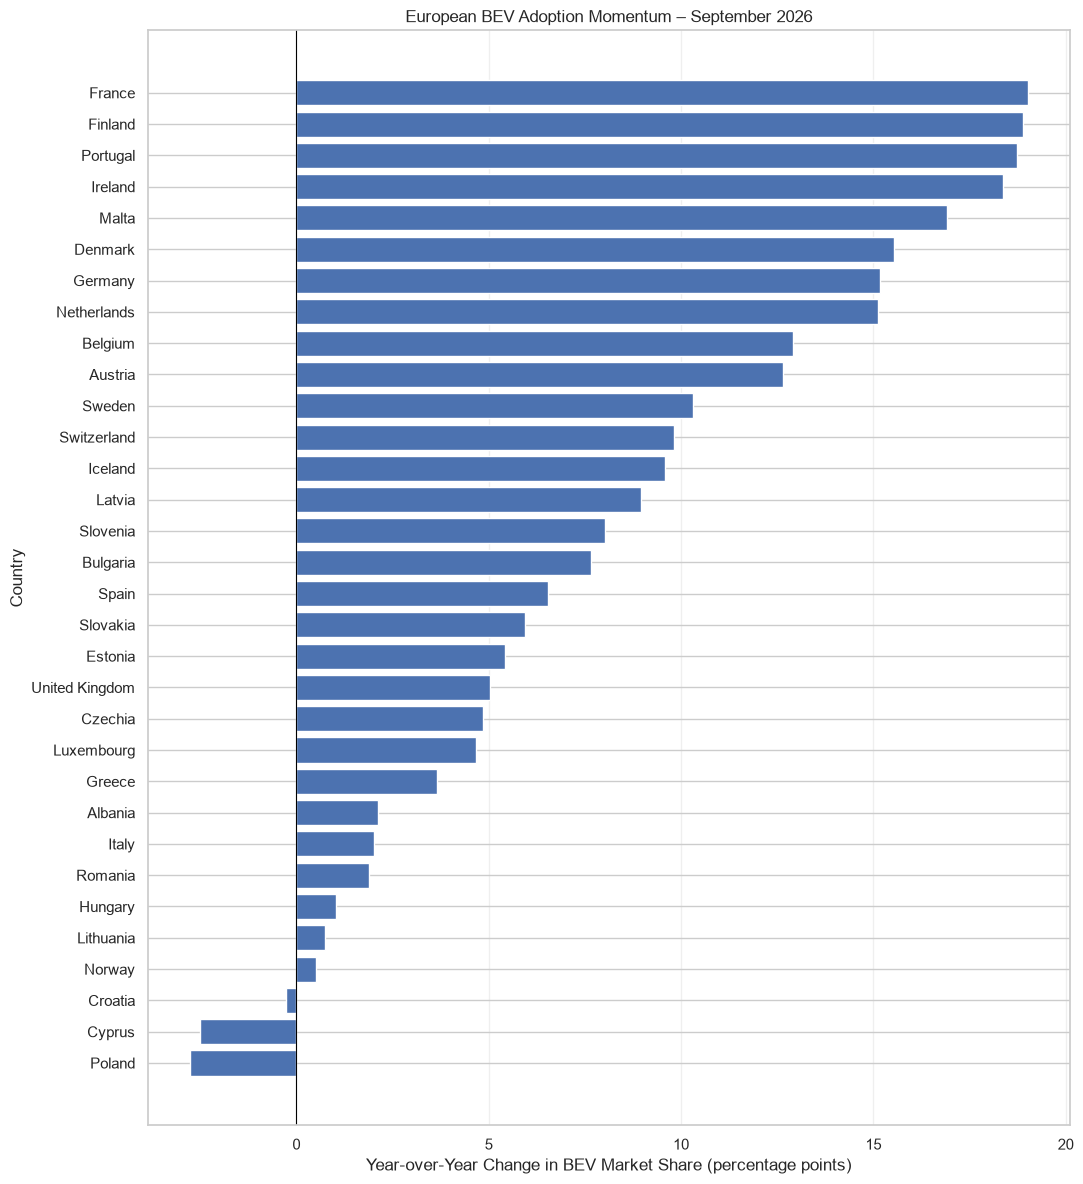

In [47]:
# Rank all countries by year-over-year BEV market share change
momentum_ranking = september_2026.sort_values("bev_share_yoy_change_pp", ascending=True)

# Create a horizontal bar chart
plt.figure(figsize=(11, 12))

plt.barh(momentum_ranking["country"], momentum_ranking["bev_share_yoy_change_pp"])

# Add a reference line at zero
plt.axvline(x=0, color="black", linewidth=0.8)

plt.title("European BEV Adoption Momentum – September 2026")
plt.xlabel("Year-over-Year Change in BEV Market Share (percentage points)")
plt.ylabel("Country")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Identifying Adoption Acceleration and Slowdowns

Year-over-year BEV market share growth provides information about adoption momentum, but it does not directly indicate whether adoption is accelerating.

To investigate changes in momentum, the current year-over-year change is compared with the corresponding year-over-year change from the previous year.

A positive difference indicates that year-over-year BEV market share growth has increased compared with the previous annual comparison. A negative difference indicates that year-over-year growth has decreased.

This measure represents a change in year-over-year growth over consecutive annual comparisons. It is used as an indicator of acceleration or deceleration, rather than a mathematical measure of long-term acceleration.

In [48]:
# Create a lookup table for the previous year's YoY change
previous_yoy = momentum_data[["country", "date", "bev_share_yoy_change_pp"]].copy()

# Shift dates forward by one year
previous_yoy["date"] = previous_yoy["date"] + pd.DateOffset(years=1)

# Rename the YoY change column
previous_yoy = previous_yoy.rename(
    columns={"bev_share_yoy_change_pp": "previous_yoy_change_pp"}
)

# Match the previous year's YoY change by exact calendar date
momentum_data = momentum_data.merge(previous_yoy, on=["country", "date"], how="left")

# Calculate the change in adoption momentum
momentum_data["adoption_acceleration_pp"] = (
    momentum_data["bev_share_yoy_change_pp"] - momentum_data["previous_yoy_change_pp"]
)

# Select September 2026
acceleration_2026 = (
    momentum_data[momentum_data["date"] == "2026-09-01"]
    .dropna(subset=["previous_yoy_change_pp"])
    .copy()
)

# Display and rank countries by adoption acceleration
acceleration_2026[
    [
        "country",
        "bev_share_yoy_change_pp",
        "previous_yoy_change_pp",
        "adoption_acceleration_pp",
    ]
].sort_values("adoption_acceleration_pp", ascending=False).round(2)

,country,bev_share_yoy_change_pp,previous_yoy_change_pp,adoption_acceleration_pp
2117,Netherlands,15.12,-2.60,17.72
3104,Sweden,10.31,-6.87,17.18
1093,France,19.01,1.97,17.04
2578,Portugal,18.73,2.40,16.33
952,Finland,18.90,3.21,15.69
2012,Malta,16.92,1.91,15.01
197,Austria,12.65,-1.31,13.96
362,Belgium,12.91,-0.37,13.28
1210,Germany,15.18,2.81,12.37
1721,Latvia,8.97,-0.41,9.38


### Key Findings: European BEV Adoption Acceleration

The acceleration analysis reveals substantial differences between countries experiencing strengthening adoption momentum and those where year-over-year growth is slowing.

- **The Netherlands and Sweden** recorded the strongest increases in adoption momentum, with acceleration values of 17.72 and 17.18 percentage points respectively. Both countries recovered from negative year-over-year growth in the previous comparison period.
- **France, Portugal and Finland** combined strong current adoption momentum with substantial positive acceleration, indicating that their BEV market shares are increasing at a faster rate than in the previous year.
- **Switzerland and Spain** both recorded positive acceleration, suggesting strengthening adoption momentum. Switzerland's acceleration was 6.57 percentage points, compared with 3.09 in Spain.
- **Denmark** maintained strong year-over-year growth of 15.54 percentage points, although its acceleration was slightly negative at −0.46 percentage points.
- **Norway** recorded negative acceleration of −2.26 percentage points. However, its year-over-year market share change remained positive at 0.52 percentage points, indicating slower growth rather than a decline.
- **Iceland** experienced the strongest deceleration, at −9.02 percentage points, despite maintaining positive year-over-year growth.
- **Poland** recorded both negative year-over-year growth and negative acceleration, suggesting a worsening decline in BEV market share.

Overall, the findings demonstrate that adoption momentum and acceleration provide different perspectives on market development. A country can experience strong current growth while its momentum is slowing, or recover rapidly after a period of declining growth.

Countries are ranked according to the change in their year-over-year BEV market share growth between September 2025 and September 2026.

Positive values indicate strengthening adoption momentum, while negative values indicate deceleration.

This visualization complements the adoption momentum ranking by showing whether the pace of BEV market share growth is increasing or decreasing.

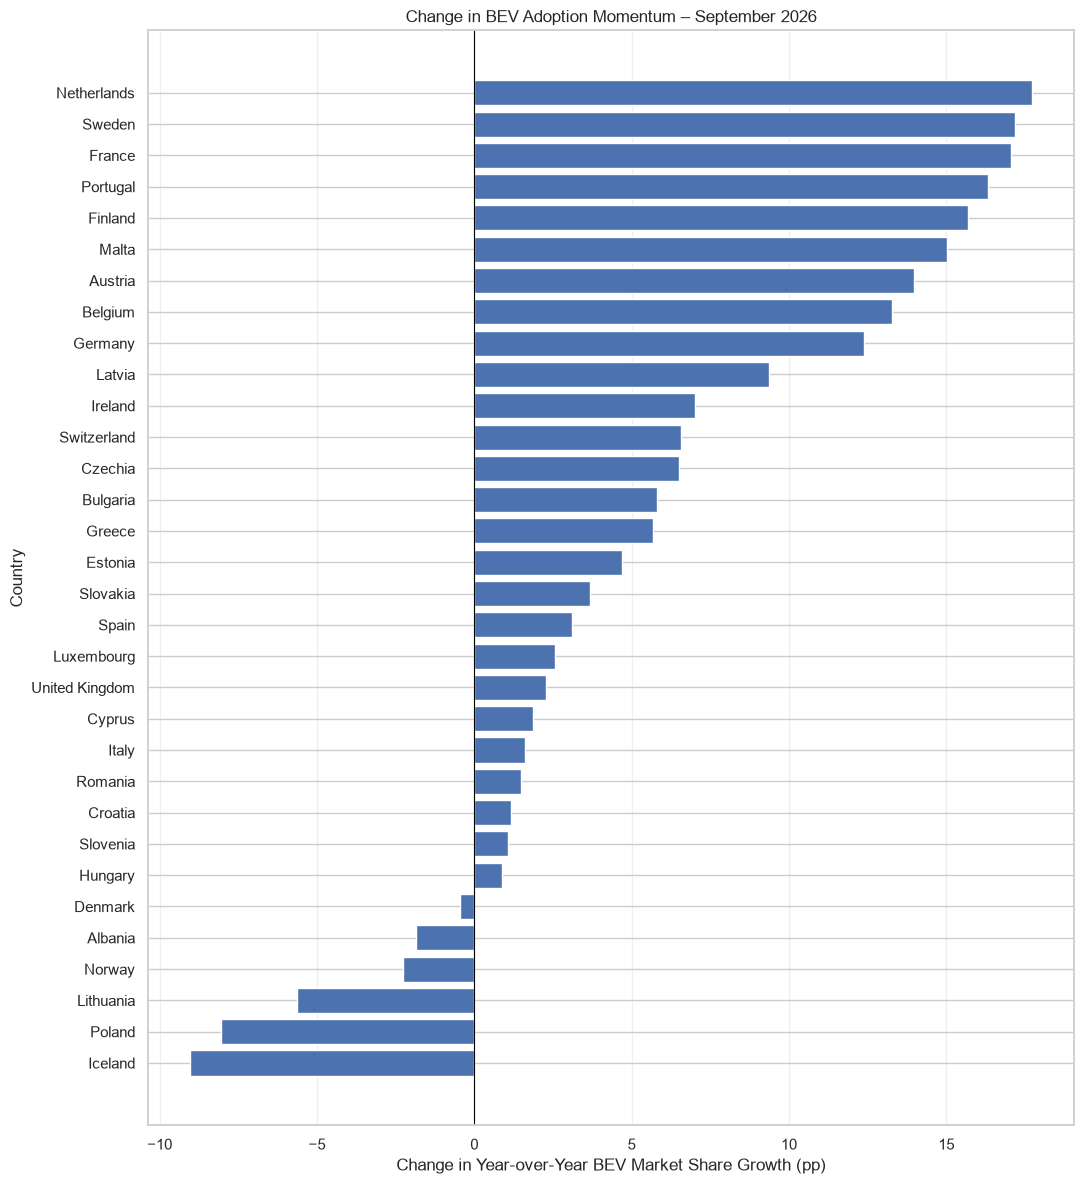

In [50]:
# Rank countries by adoption acceleration
acceleration_ranking = acceleration_2026.sort_values(
    "adoption_acceleration_pp", ascending=True
)

# Create a horizontal bar chart
plt.figure(figsize=(11, 12))

plt.barh(
    acceleration_ranking["country"], acceleration_ranking["adoption_acceleration_pp"]
)

# Add a reference line at zero
plt.axvline(x=0, color="black", linewidth=0.8)

plt.title("Change in BEV Adoption Momentum – September 2026")
plt.xlabel("Change in Year-over-Year BEV Market Share Growth (pp)")
plt.ylabel("Country")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Projecting Future BEV Adoption Momentum

The final BEV market share forecasts are used to estimate future year-over-year adoption momentum across the 32 eligible European countries.

For each country, the projected monthly BEV market share is compared with the observed market share from the corresponding month one year earlier.

This provides an indication of how year-over-year BEV market share growth could evolve between October 2026 and September 2027.

The results are derived from the previously selected forecasting models and should be interpreted as model-based estimates rather than guaranteed future outcomes.

In [51]:
# Calculate projected year-over-year adoption momentum

future_momentum = []

for country, forecast in final_forecasts.items():

    # Retrieve the historical observations from one year earlier
    historical_values = country_series[country].loc["2025-10-01":"2026-09-01"]

    # Compare forecasted values with the corresponding historical months
    for date, forecast_value in forecast.items():

        previous_value = historical_values.loc[date - pd.DateOffset(years=1)]

        future_momentum.append(
            {
                "country": country,
                "date": date,
                "forecast_bev_share_pct": forecast_value,
                "previous_year_bev_share_pct": previous_value,
                "forecast_yoy_change_pp": forecast_value - previous_value,
            }
        )

# Create the future momentum DataFrame
future_momentum_df = pd.DataFrame(future_momentum)

# Display the results
display(
    future_momentum_df.round(
        {
            "forecast_bev_share_pct": 2,
            "previous_year_bev_share_pct": 2,
            "forecast_yoy_change_pp": 2,
        }
    )
)

# Validate the future momentum dataset

print("Countries:", future_momentum_df["country"].nunique())
print("Total observations:", len(future_momentum_df))
print("Missing values:", future_momentum_df.isna().sum().sum())
print("Forecast period:", future_momentum_df["date"].min(),
      "to", future_momentum_df["date"].max())

,country,date,forecast_bev_share_pct,previous_year_bev_share_pct,forecast_yoy_change_pp
0,Albania,2026-10-01,10.89,9.28,1.61
1,Albania,2026-11-01,10.89,11.29,-0.40
2,Albania,2026-12-01,10.89,10.90,-0.01
3,Albania,2027-01-01,10.89,13.27,-2.38
4,Albania,2027-02-01,10.89,14.53,-3.64
...,...,...,...,...,...
379,United Kingdom,2027-05-01,30.00,27.34,2.66
380,United Kingdom,2027-06-01,31.13,30.00,1.13
381,United Kingdom,2027-07-01,29.31,27.53,1.78
382,United Kingdom,2027-08-01,32.09,29.78,2.31


Countries: 32
Total observations: 384
Missing values: 0
Forecast period: 2026-10-01 00:00:00 to 2027-09-01 00:00:00


In [52]:
# Summarise projected adoption momentum by country

future_momentum_summary = (
    future_momentum_df.groupby("country")
    .agg(
        average_yoy_change_pp=("forecast_yoy_change_pp", "mean"),
        latest_yoy_change_pp=("forecast_yoy_change_pp", "last"),
        minimum_yoy_change_pp=("forecast_yoy_change_pp", "min"),
        maximum_yoy_change_pp=("forecast_yoy_change_pp", "max")
    )
    .sort_values("average_yoy_change_pp", ascending=False)
    .reset_index()
)

display(future_momentum_summary.round(2))

,country,average_yoy_change_pp,latest_yoy_change_pp,minimum_yoy_change_pp,maximum_yoy_change_pp
0,Portugal,15.80,3.63,3.63,21.58
1,Slovenia,14.55,16.79,7.41,18.13
2,Finland,13.98,0.00,0.00,26.33
3,Denmark,13.95,11.39,7.34,17.17
4,Malta,13.87,5.77,1.64,22.96
5,Iceland,12.80,6.45,-2.75,35.38
6,France,11.49,0.00,0.00,17.32
7,Belgium,11.15,7.02,7.02,14.66
8,Austria,8.86,0.00,0.00,13.07
9,Bulgaria,8.44,7.70,6.29,10.25


### Interpretation

The projected year-over-year changes reveal considerable differences in expected BEV adoption across the 32 European countries between October 2026 and September 2027.

Portugal records the highest average projected year-over-year increase, at 15.80 percentage points, followed by Slovenia (14.55 pp), Finland (13.98 pp), Denmark (13.95 pp) and Malta (13.87 pp).

Other established markets, including France, Belgium and Germany, also show positive projected growth. Norway, by comparison, has a relatively modest average projected increase of 1.22 percentage points, reflecting its already high level of BEV adoption.

Some countries show negative average projected year-over-year changes. Cyprus records the lowest average at −2.63 percentage points, followed by Croatia, Albania, Poland and Romania.

The results also highlight differences in forecast stability. Iceland, for example, has a particularly wide range of projected monthly changes, suggesting greater uncertainty in its monthly forecast trajectory.

Latvia and Lithuania show no projected year-over-year change because their selected Seasonal Naive models repeat the corresponding monthly values from the previous year.

Overall, the projections suggest different potential adoption trajectories across European markets. However, they remain model-based estimates derived from historical patterns and should not be interpreted as guaranteed future outcomes.

## Exporting Forecast Results for the Streamlit Dashboard

The final forecast results and projected year-over-year adoption momentum are combined into a single dataset for use in the Streamlit dashboard.

The dataset includes country identifiers, forecast dates, predicted BEV market shares, projected year-over-year changes and the selected forecasting method for each country.

The exported dataset supports interactive comparisons between historical BEV adoption and future projections across the 32 eligible European countries.

In [53]:
# Combine forecast values and projected adoption momentum

forecast_export_df = final_forecast_df.merge(
    future_momentum_df[
        ["country", "date", "forecast_yoy_change_pp"]
    ],
    on=["country", "date"],
    how="left",
    validate="one_to_one"
)

# Add the selected forecasting method for each country
model_mapping = best_models[
    ["Country", "Method"]
].rename(
    columns={
        "Country": "country",
        "Method": "forecast_model"
    }
)

forecast_export_df = forecast_export_df.merge(
    model_mapping,
    on="country",
    how="left",
    validate="many_to_one"
)

# Add country codes for dashboard visualisations
country_codes = (
    forecast_data[["country", "country_code"]]
    .drop_duplicates()
)

forecast_export_df = forecast_export_df.merge(
    country_codes,
    on="country",
    how="left",
    validate="many_to_one"
)

# Sort the final dataset
forecast_export_df = forecast_export_df.sort_values(
    ["country", "date"]
).reset_index(drop=True)

# Display the final dataset
display(forecast_export_df.head(15))

print("Dataset shape:", forecast_export_df.shape)
print("Countries:", forecast_export_df["country"].nunique())
print("Missing values:")
display(forecast_export_df.isna().sum())

,country,date,forecast_bev_share_pct,forecast_yoy_change_pp,forecast_model,country_code
0,Albania,2026-10-01,10.89,1.61,Naive,ALB
1,Albania,2026-11-01,10.89,-0.40,Naive,ALB
2,Albania,2026-12-01,10.89,-0.01,Naive,ALB
3,Albania,2027-01-01,10.89,-2.38,Naive,ALB
4,Albania,2027-02-01,10.89,-3.64,Naive,ALB
5,Albania,2027-03-01,10.89,-8.00,Naive,ALB
6,Albania,2027-04-01,10.89,-5.67,Naive,ALB
7,Albania,2027-05-01,10.89,-0.48,Naive,ALB
8,Albania,2027-06-01,10.89,1.73,Naive,ALB
9,Albania,2027-07-01,10.89,2.93,Naive,ALB


Dataset shape: (384, 6)
Countries: 32
Missing values:


country                   0
date                      0
forecast_bev_share_pct    0
forecast_yoy_change_pp    0
forecast_model            0
country_code              0
dtype: int64

In [54]:
# Export the final forecast dataset for Streamlit

forecast_export_df.to_csv(
    "../data/cleaned/ev_forecasts.csv",
    index=False
)

print("Forecast dataset exported successfully.")

Forecast dataset exported successfully.
